# NASA UMM to `Geocroissant` Conversion 🥐

This notebook shows NASA Unified Metadata Model (UMM) records to GeoCroissant format. It authenticates with NASA Earthdata using `earthaccess`, queries collection (UMM-C) and granule (UMM-G) metadata for Harmonized Landsat Sentinel-2 (HLS) imagery.

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="150" style="float: right; margin-left: 20px;">

## Metadata mapping overview

| NASA UMM-C / UMM-G property | GeoCroissant property |
|---|---|
| Collection `EntryTitle` / `Abstract` | `name` / `description` |
| Collection `DOI.DOI` | `url` |
| Collection `Version` | `version` |
| CMR Granule search API | `geocr:recordEndpoint` |
| `HORIZONTAL_CS_CODE` | `geocr:coordinateReferenceSystem` |
| `SPATIAL_RESOLUTION` | `geocr:spatialResolution` |
| `TemporalExtents.TemporalResolution` | `geocr:temporalResolution` |
| Granule `SpatialExtent` bounds | `spatialCoverage` |
| Granule `TemporalExtent` | `temporalCoverage` |
| Sentinel-2 MSI 13 spectral bands | `geocr:bandConfiguration` |
| Spectral band center wavelengths & bandwidths | `geocr:spectralBandMetadata` |
| Granule `RelatedUrls` (GeoTIFF COGs) | `distribution` |
| `GranuleUR`, `datetime`, `cloud_cover`, band URLs | `recordSet` |


In [1]:
# Dependencies installation
#!pip install earthaccess mlcroissant rasterio matplotlib numpy

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import rasterio

import earthaccess
import mlcroissant as mlc

## 1. Authentication and collection query

We authenticate using `earthaccess.login()` and retrieve collection metadata (UMM-C) 

In [3]:
# Authenticate with NASA Earthdata Login
auth = earthaccess.login()
print(f"Authenticated: {auth.authenticated}")

# Query collection metadata (UMM-C)
collection_id = "C2021957295-LPCLOUD"
collections = earthaccess.search_datasets(concept_id=collection_id)
coll_umm = collections[0]["umm"]

print(f"Collection Title: {coll_umm['EntryTitle']}")
print(f"Short Name:       {coll_umm.get('ShortName')}")
print(f"Version:          {coll_umm.get('Version')}")
print(f"DOI:              {coll_umm.get('DOI', {}).get('DOI')}")

Authenticated: True
Collection Title: HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0
Short Name:       HLSS30
Version:          2.0
DOI:              10.5067/HLS/HLSS30.002


## 2. Granule search over Huntsville, Alabama

In [4]:
# Huntsville coordinates and bounding box
huntsville_lat = 34.7304
huntsville_lon = -86.5861
bbox = [
    huntsville_lon - 0.5,
    huntsville_lat - 0.5,
    huntsville_lon + 0.5,
    huntsville_lat + 0.5,
]

# Query granules with cloud cover filter
query = (
    earthaccess.DataGranules()
    .concept_id(collection_id)
    .bounding_box(*bbox)
    .cloud_cover(0, 10)
)

granules = list(query.get(5))
print(f"Retrieved {len(granules)} low cloud-cover granules over Huntsville, AL")

# Select target granule
selected_granule = granules[0]
umm = selected_granule["umm"]
granule_ur = umm["GranuleUR"]
attrs = {
    a["Name"]: a["Values"][0]
    for a in umm.get("AdditionalAttributes", [])
    if a.get("Values")
}

print(f"\nSelected Granule ID: {granule_ur}")
print(
    "Acquisition Time:   "
    f" {umm.get('TemporalExtent', {}).get('RangeDateTime', {}).get('BeginningDateTime')}"
)
print(f"Cloud Cover:         {attrs.get('CLOUD_COVERAGE')}%")
print(f"MGRS Tile ID:        {attrs.get('MGRS_TILE_ID')}")
print(f"Coordinate System:   {attrs.get('HORIZONTAL_CS_CODE')}")
print(f"Spatial Resolution:  {attrs.get('SPATIAL_RESOLUTION')} m")

Retrieved 5 low cloud-cover granules over Huntsville, AL

Selected Granule ID: HLS.S30.T16SED.2016011T162642.v2.0
Acquisition Time:    2016-01-11T16:37:13.420Z
Cloud Cover:         3%
MGRS Tile ID:        16SED
Coordinate System:   EPSG:32616
Spatial Resolution:  30.0 m


/home/xuan/miniconda3/envs/dl/lib/python3.11/site-packages/earthaccess/results.py:343: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()


## 3. Convert NASA UMM to GeoCroissant

In [5]:
# Sentinel-2 MSI spectral bands (band name, common name, center wavelength nm, bandwidth nm, resolution m)
S2_BANDS = [
    ("B01", "Coastal Aerosol", 443.0, 20.0, 30.0),
    ("B02", "Blue", 490.0, 65.0, 30.0),
    ("B03", "Green", 560.0, 35.0, 30.0),
    ("B04", "Red", 665.0, 30.0, 30.0),
    ("B05", "Red Edge 1", 705.0, 15.0, 30.0),
    ("B06", "Red Edge 2", 740.0, 15.0, 30.0),
    ("B07", "Red Edge 3", 783.0, 20.0, 30.0),
    ("B08", "NIR Broad", 842.0, 115.0, 30.0),
    ("B8A", "NIR Narrow", 865.0, 20.0, 30.0),
    ("B09", "Water Vapour", 945.0, 20.0, 30.0),
    ("B10", "Cirrus", 1375.0, 30.0, 30.0),
    ("B11", "SWIR 1", 1610.0, 90.0, 30.0),
    ("B12", "SWIR 2", 2190.0, 180.0, 30.0),
]

# Verified SHA-256 checksums computed directly from the NASA LP DAAC COG files
SHA256_CHECKSUMS = {
    "B01": "509d9fcc65fc23ea1db3cec81b48172dc97984b5aaee07e26939964487fecd86",
    "B02": "72b23f5c1ed4d18aac771db4cc480904d33fc7aa1c5e61b2a26121dae2d7dc8c",
    "B03": "b28358a69f873a89ba2ad26678b05e2c32de14eb88ed103ef793d10ae5582139",
    "B04": "bc907f529b983a472e737416dd6b6631e2b70458f28cc10e80a177475e95cf75",
    "B05": "c5f1cb568fd5b036467246a06d81a0251bd0639e9ab93fb85ab0928f322dc8cc",
    "B06": "d8ed6a699a5a8d47106773406084aea6f08db0aa394156b73747f588d0e5789f",
    "B07": "d358634e3d7c2e3ed36c77dd2f4ce74f7800acce530c58adff203125c6836979",
    "B08": "0d3f5c36e8263ba9b5a11d684c04e343982e2ba5868d0007b79f4af44e77c844",
    "B8A": "0d13e82b0b64d9c8a09520a478ee86ffd28a7ca44079f63f1be2ac70e350f90a",
    "B09": "614bc351fabf7e0e208396a90c487728f6d7a9658625addc4cbfdf8ca598cee9",
    "B10": "b78323518feba3c719669579b3d6185b09fc0478b49bebb5fbc5f4677002fb72",
    "B11": "72c430e3bb54e3cc9795941f4708247baec3e9a8dc17908404566df122d0e4ca",
    "B12": "3551fd03c4f50f5c896d9a3ac0aa953c06e6ab9080b001be8f5346bdce98fe22",
}

# Extract band URLs from RelatedUrls
band_urls = {}
for u in umm.get("RelatedUrls", []):
    url = u.get("URL", "")
    if (
        u.get("Type") == "GET DATA"
        and url.startswith("https://")
        and url.endswith(".tif")
    ):
        for b_name, _, _, _, _ in S2_BANDS:
            if url.endswith(f".{b_name}.tif"):
                band_urls[b_name] = url

# 1. Distribution: FileObjects for all spectral bands with verified SHA-256 checksums
file_objects = [
    mlc.FileObject(
        id=f"{granule_ur}_{b_name}",
        name=f"{b_name}.tif",
        description=f"{b_desc} ({b_name}) at {res}m resolution",
        content_url=band_urls[b_name],
        encoding_formats=["image/tiff; application=geotiff; profile=cloud-optimized"],
        sha256=SHA256_CHECKSUMS[b_name],
    )
    for b_name, b_desc, cw, bw, res in S2_BANDS
    if b_name in band_urls
]

# 2. Spectral band metadata
spectral_bands = [
    mlc.SpectralBand(
        name=b_name,
        center_wavelength=mlc.QuantitativeValue(value=cw, unitText="nm"),
        bandwidth=mlc.QuantitativeValue(value=bw, unitText="nm"),
    )
    for b_name, _, cw, bw, _ in S2_BANDS
]

# 3. RecordSet and Field definitions
start_time = (
    umm.get("TemporalExtent", {}).get("RangeDateTime", {}).get("BeginningDateTime", "")
)
cloud_val = float(attrs.get("CLOUD_COVERAGE", 0.0))
epsg_val = attrs.get("HORIZONTAL_CS_CODE", "EPSG:32616")
mgrs_val = attrs.get("MGRS_TILE_ID", "Unknown")
platform_val = umm.get("Platforms", [{}])[0].get("ShortName", "Sentinel-2A")

record = {
    "granules/granule_ur": granule_ur,
    "granules/datetime": start_time,
    "granules/cloud_cover": cloud_val,
    "granules/mgrs_tile": mgrs_val,
    "granules/platform": platform_val,
    "granules/epsg": epsg_val,
}
fields = [
    mlc.Field(
        id="granules/granule_ur", name="granule_ur", data_types=[mlc.DataType.TEXT]
    ),
    mlc.Field(id="granules/datetime", name="datetime", data_types=[mlc.DataType.DATE]),
    mlc.Field(
        id="granules/cloud_cover", name="cloud_cover", data_types=[mlc.DataType.FLOAT]
    ),
    mlc.Field(
        id="granules/mgrs_tile", name="mgrs_tile", data_types=[mlc.DataType.TEXT]
    ),
    mlc.Field(id="granules/platform", name="platform", data_types=[mlc.DataType.TEXT]),
    mlc.Field(id="granules/epsg", name="epsg", data_types=[mlc.DataType.TEXT]),
]

for b_name in band_urls:
    col_id = f"granules/{b_name.lower()}_url"
    record[col_id] = band_urls[b_name]
    fields.append(
        mlc.Field(
            id=col_id, name=f"{b_name.lower()}_url", data_types=[mlc.DataType.URL]
        )
    )

granules_rs = mlc.RecordSet(
    id="granules",
    name="granules",
    description="NASA HLS Sentinel-2 granules with quality metrics and band URLs",
    data=[record],
    fields=fields,
)

# 4. Spatial extent box
points = (
    umm.get("SpatialExtent", {})
    .get("HorizontalSpatialDomain", {})
    .get("Geometry", {})
    .get("GPolygons", [{}])[0]
    .get("Boundary", {})
    .get("Points", [])
)
if points:
    lats = [p["Latitude"] for p in points]
    lons = [p["Longitude"] for p in points]
    spatial_box = f"{min(lats):.4f} {min(lons):.4f} {max(lats):.4f} {max(lons):.4f}"
else:
    spatial_box = f"{bbox[1]} {bbox[0]} {bbox[3]} {bbox[2]}"

# 5. Complete Metadata
metadata = mlc.Metadata(
    name="nasa-hls-sentinel2-s30",
    description=coll_umm.get(
        "Abstract",
        "NASA HLS Sentinel-2 Multi-spectral Surface Reflectance Daily Global 30m v2.0",
    ),
    cite_as=(
        "@misc{nasa_hls_s30, title={HLS Sentinel-2 Multi-spectral Instrument Surface"
        " Reflectance Daily Global 30m v2.0}, DOI={10.5067/HLS/HLSS30.002},"
        " publisher={LP DAAC}, author={NASA}, year={2021}}"
    ),
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/1.0",
    ],
    url="https://doi.org/10.5067/HLS/HLSS30.002",
    date_published="2021-08-20",
    license="https://creativecommons.org/publicdomain/zero/1.0/",
    version=coll_umm.get("Version", "2.0"),
    keywords=[
        "remote sensing",
        "nasa",
        "cmr",
        "hls",
        "sentinel-2",
        "earth-observation",
        "geocroissant",
    ],
    record_endpoint=f"https://cmr.earthdata.nasa.gov/search/granules.umm_json?collection_concept_id={collection_id}",
    coordinate_reference_system=epsg_val,
    spatial_resolution=mlc.QuantitativeValue(value=30.0, unitText="m"),
    temporal_resolution=mlc.QuantitativeValue(value=1.0, unitText="d"),
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": spatial_box,
        },
    },
    band_configuration=mlc.BandConfiguration(
        total_bands=len(S2_BANDS),
        band_names_list=[b[0] for b in S2_BANDS],
    ),
    spectral_band_metadata=spectral_bands,
    distribution=file_objects,
    record_sets=[granules_rs],
)

print(
    f"GeoCroissant Metadata instantiated with {len(file_objects)} FileObjects with"
    f" verified SHA-256 and {len(spectral_bands)} spectral bands."
)

GeoCroissant Metadata instantiated with 13 FileObjects with verified SHA-256 and 13 spectral bands.


In [6]:
# Serialize to JSON-LD
output_json = "nasa_hls_geocroissant.json"
with open(output_json, "w") as f:
    json.dump(metadata.to_json(), f, indent=2)

print(f"Metadata saved to {output_json}")

Metadata saved to nasa_hls_geocroissant.json


## 4. Validate metadata

We validate the generated JSON-LD document using the `mlcroissant` command-line validator.


In [7]:
!mlcroissant validate --jsonld=nasa_hls_geocroissant.json

I1107 10:34:41.409085 124618162018112 validate.py:53] Done.


## 5. Load dataset and inspect records

We load the dataset using `mlcroissant` and iterate through the materialized records.


In [8]:
dataset = mlc.Dataset(jsonld="nasa_hls_geocroissant.json")
print(f"Dataset Name:     {dataset.metadata.name}")
print(f"Conforms To:      {dataset.metadata.conforms_to}")
print(f"Record Endpoint:  {getattr(dataset.metadata, 'record_endpoint', None)}")
print(
    "CRS:             "
    f" {getattr(dataset.metadata, 'coordinate_reference_system', None)}"
)

print("\nMaterialized Granule Record:")
for record in dataset.records("granules"):
    for k, v in record.items():
        print(f"  {k}: {v}")

Dataset Name:     nasa-hls-sentinel2-s30
Conforms To:      ['http://mlcommons.org/croissant/1.1', 'http://mlcommons.org/croissant/geo/1.0']
Record Endpoint:  https://cmr.earthdata.nasa.gov/search/granules.umm_json?collection_concept_id=C2021957295-LPCLOUD
CRS:              EPSG:32616

Materialized Granule Record:
  granules/b01_url: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T16SED.2016011T162642.v2.0/HLS.S30.T16SED.2016011T162642.v2.0.B01.tif
  granules/b02_url: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T16SED.2016011T162642.v2.0/HLS.S30.T16SED.2016011T162642.v2.0.B02.tif
  granules/b03_url: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T16SED.2016011T162642.v2.0/HLS.S30.T16SED.2016011T162642.v2.0.B03.tif
  granules/b04_url: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T16SED.2016011T162642.v2.0/HLS.S30.T16SED.2016011T162642.v2.0.B04.tif
 

## 6. satellite imagery visualization

Loaded record: granules
Found bands: B02, B03, B04


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

B04 shape: (3660, 3660)
B03 shape: (3660, 3660)
B02 shape: (3660, 3660)


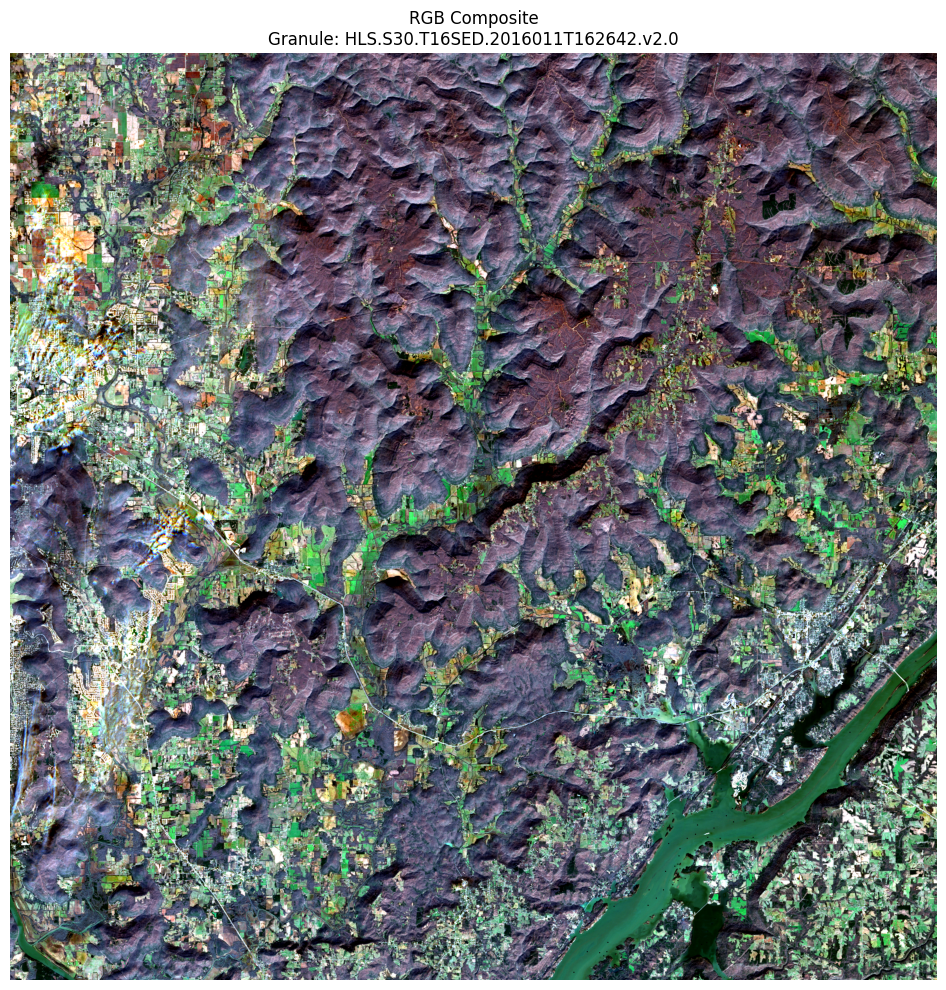

In [9]:
# Constants
SCALE_FACTOR = 0.0001
BAND_LABELS = {
    "B04": ("Red", "665nm"),
    "B03": ("Green", "560nm"),
    "B02": ("Blue", "490nm"),
}

# Load GeoCroissant metadata
with open("nasa_hls_geocroissant.json", "r") as f:
    data = json.load(f)

# Access the recordSet
record = data["recordSet"][0]
print(f"Loaded record: {record['name']}")

# Extract RGB band URLs from the main distribution section
band_urls = {}
for dist in data["distribution"]:
    url = dist.get("contentUrl", "")
    if ".tif" in url:
        for band in BAND_LABELS:
            if f"{band}.tif" in url:
                band_urls[band] = url

print(f"Found bands: {', '.join(sorted(band_urls.keys()))}")

# Open RGB GeoTIFFs directly via earthaccess and rasterio
files = earthaccess.open([band_urls["B04"], band_urls["B03"], band_urls["B02"]])

band_data = {}
for band, f in zip(["B04", "B03", "B02"], files):
    with rasterio.open(f) as dataset:
        band_data[band] = dataset.read(1)
        print(f"{band} shape: {band_data[band].shape}")


# Preprocessing: 2% to 98% percentile contrast normalization (matching plot_band)
def scale_and_normalize(data):
    valid = data[data > 0]
    if valid.size == 0:
        return np.zeros_like(data, dtype=np.float32)
    p2, p98 = np.percentile(valid, 2), np.percentile(valid, 98)
    if p98 == p2:
        return np.zeros_like(data, dtype=np.float32)
    arr = (data.astype(np.float32) - p2) / (p98 - p2)
    return np.clip(arr, 0, 1)


# RGB composite function with center crop to focus on the scene without off-swath nodata
def plot_rgb(ax, band_data, center_crop=True):
    try:
        if center_crop:
            # Center on the region of interest (Huntsville / Tennessee River)
            r_slice = slice(1000, 2800)
            c_slice = slice(1400, 3200)
        else:
            r_slice = slice(None)
            c_slice = slice(None)

        r = scale_and_normalize(band_data["B04"][r_slice, c_slice])  # Red
        g = scale_and_normalize(band_data["B03"][r_slice, c_slice])  # Green
        b = scale_and_normalize(band_data["B02"][r_slice, c_slice])  # Blue
        rgb = np.dstack([r, g, b])
        ax.imshow(rgb)
        ax.set_title(
            f"RGB Composite\nGranule: {granule_ur}",
            fontsize=12,
        )
        ax.axis("off")
    except Exception as e:
        ax.set_title("RGB Composite Failed", fontsize=10)
        print(f"RGB composite error: {e}")


# Plot centered RGB composite
fig, ax = plt.subplots(figsize=(10, 10))
plot_rgb(ax, band_data, center_crop=True)
plt.tight_layout()
plt.show()